# RetailLens | Customer segmentation & retention intelligence
**SQL · RFM · behavioral features · K-Means · Ward clustering · GMM · PCA**

This walkthrough includes real outputs from the full UCI Online Retail II dataset. Start with the source, follow the SQL and model comparisons, then interpret the untouched future-period results. Raw transaction records are invoice **line items**, not distinct orders.

**Local:** extract the archive, install `requirements.txt` into Python 3.12, and select that environment as the notebook kernel. **Colab:** the next cell prompts for the delivered project ZIP when needed and uses an isolated Python environment for the pipeline. Colab setup requires internet and has not been run in this environment; local cells have been executed successfully.


In [1]:
from pathlib import Path
import os, sys, subprocess, json, sqlite3, zipfile
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

candidates = [Path.cwd(), Path.cwd()/"customer_segmentation", Path("/content/customer_segmentation")]
project = next((p for p in candidates if (p/"run.py").exists()), None)
if project is None and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()  # Select RetailLens_Customer_Segmentation.zip.
    archives = [Path(name) for name in uploaded if name.endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Upload exactly one project ZIP")
    destination = Path("/content").resolve()
    with zipfile.ZipFile(archives[0]) as archive:
        for member in archive.namelist():
            if not (destination/member).resolve().is_relative_to(destination):
                raise ValueError("Unsafe archive path")
        archive.extractall(destination)
    project = destination/"customer_segmentation"
if project is None or not (project/"run.py").exists():
    raise FileNotFoundError("Extract the full project ZIP and open this notebook inside customer_segmentation")
project = project.resolve()
os.chdir(project)
RUN_PY = sys.executable
if IN_COLAB:
    env = project/".colab_env"
    if not (env/"bin/python").exists():
        subprocess.run([sys.executable,"-m","venv",str(env)],check=True)
    RUN_PY = str(env/"bin/python")
    subprocess.run([RUN_PY,"-m","pip","install","-q","-r","requirements.txt"],check=True)
print("Project located. Pipeline Python is configured.")


Project located. Pipeline Python is configured.


## 1. Run the audited pipeline
The first run streams both original Excel sheets into SQLite. Later runs validate the source checksum and reuse that database. The algorithm operates on customer aggregates. The model is frozen before future outcomes are attached.


In [2]:
result = subprocess.run([RUN_PY,"-u","run.py"],check=True,capture_output=True,text=True)
print(result.stdout)


[1/5] Data ingestion and audit
[2/5] SQL features before 2011-09-10; holdout until 2011-12-09 exclusive
[3/5] Compare models on 5,256 historical customers
  KMeans_2: silhouette=0.304; min share=43.7%
  KMeans_3: silhouette=0.323; min share=7.7%
  KMeans_4: silhouette=0.311; min share=7.7%
  KMeans_5: silhouette=0.320; min share=1.4%
  KMeans_6: silhouette=0.333; min share=1.3%
  KMeans_7: silhouette=0.308; min share=1.2%
  KMeans_8: silhouette=0.303; min share=1.2%
  Hierarchical_2: silhouette=0.307; min share=29.8%
  Hierarchical_3: silhouette=0.317; min share=5.7%
  Hierarchical_4: silhouette=0.274; min share=5.7%
  Hierarchical_5: silhouette=0.287; min share=4.7%
  Hierarchical_6: silhouette=0.290; min share=4.7%
  Hierarchical_7: silhouette=0.255; min share=4.7%
  Hierarchical_8: silhouette=0.272; min share=1.2%
  GMM_2: silhouette=0.317; min share=35.9%
  GMM_3: silhouette=0.237; min share=30.0%
  GMM_4: silhouette=0.241; min share=7.7%
  GMM_5: silhouette=0.195; min share=3.7%
 

## 2. Validate counting, refunds and time boundaries
The fixtures have hand-calculated answers: invoices versus items, purchase/refund arithmetic, SQL order gaps, exact duplicates, exclusive cutoff, unseen future customers, missing gaps and censored cohorts. They are test fixtures, not substituted project data.


In [3]:
test_result = subprocess.run([RUN_PY,"-m","unittest","discover","-s","tests","-v"],capture_output=True,text=True)
print(test_result.stdout + test_result.stderr)
test_result.check_returncode()


test_censored_cohort_cells_not_zero (test_pipeline.SQLTests.test_censored_cohort_cells_not_zero) ... ok
test_cleaning_reasons (test_pipeline.SQLTests.test_cleaning_reasons) ... ok
test_cutoff_exclusive_and_future_customers_excluded (test_pipeline.SQLTests.test_cutoff_exclusive_and_future_customers_excluded) ... ok
test_exact_duplicate_removed (test_pipeline.SQLTests.test_exact_duplicate_removed) ... ok
test_frequency_counts_invoices_not_items (test_pipeline.SQLTests.test_frequency_counts_invoices_not_items) ... ok
test_future_edits_do_not_change_features (test_pipeline.SQLTests.test_future_edits_do_not_change_features) ... ok
test_single_order_gap_is_missing (test_pipeline.SQLTests.test_single_order_gap_is_missing) ... ok
test_window_gap_and_recency (test_pipeline.SQLTests.test_window_gap_and_recency) ... ok
test_missing_gap_finite_and_flag_kept (test_pipeline.TransformTests.test_missing_gap_finite_and_flag_kept) ... ok
test_persona_rule_priority (test_pipeline.TransformTests.test_pers

## 3. Inspect the full-data audit


In [4]:
import pandas as pd
audit = json.loads(Path("outputs/data_audit.json").read_text())
metrics = json.loads(Path("outputs/metrics.json").read_text())
print("Raw records:", f"{audit['raw_rows']:,}")
print("Exact normalized duplicates:", f"{audit['exact_duplicates_removed']:,}")
print(pd.Series(audit["row_disposition"],name="rows").to_string())
print("Source SHA-256:",audit["source_sha256"])


Raw records: 1,067,371
Exact normalized duplicates: 34,335
missing_customer                      235151
non_merchandise_code                    3662
nonpositive_price_or_zero_quantity        60
purchase                              776577
return                                 17586
Source SHA-256: bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980


## 4. Read the actual feature SQL
Each aggregation has one row per customer before the final joins. `LAG` calculates consecutive order gaps. `ROW_NUMBER` selects the dominant country deterministically. Every source CTE respects the historical cutoff.


In [5]:
print(Path("sql/customer_features.sql").read_text())


-- SQLite 3.25+. :cutoff is an EXCLUSIVE feature boundary; :recent_start = cutoff - 90d.
-- Frequency counts invoices, not line items. Returns remain a separate ledger.
WITH purchases AS (
 SELECT * FROM lines WHERE reason='purchase' AND invoice_date < :cutoff
), orders AS (
 SELECT customer_id,invoice,MIN(invoice_date) AS order_date,
        SUM(value) AS order_value,SUM(quantity) AS basket_units,COUNT(*) AS line_count
 FROM purchases GROUP BY customer_id,invoice
), ordered AS (
 SELECT *,LAG(order_date) OVER (PARTITION BY customer_id ORDER BY order_date,invoice) AS previous_order,
        ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY order_date,invoice) AS order_sequence
 FROM orders
), order_stats AS (
 SELECT customer_id,COUNT(*) AS frequency,SUM(order_value) AS monetary,
        AVG(order_value) AS avg_order_value,AVG(basket_units) AS avg_basket_units,
        MIN(order_date) AS first_purchase,MAX(order_date) AS last_purchase,
        CAST(julianday(:cutoff)-julianday(date(

## 5. Inspect raw customer features before modeling transforms


In [6]:
customers = pd.read_csv("outputs/customer_segments.csv",dtype={"customer_id":str})
fields = ["customer_id","recency","frequency","monetary","unique_products","avg_gap_days","single_order"]
print(customers[fields].head(10).to_string(index=False))
print("Customer rows:",len(customers),"| Historical invoices:",int(customers.frequency.sum()))
assert customers.customer_id.is_unique
assert (pd.to_datetime(customers.last_purchase) < pd.Timestamp(metrics["cutoff_exclusive"])).all()
print("One row per customer and historical cutoff checks passed.")


customer_id  recency  frequency  monetary  unique_products  avg_gap_days  single_order
      12346      235          3  77352.96               25    160.935069             0
      12347       39          6   3402.39              107     54.953889             0
      12348      158          4   1388.40               24     63.275000             0
      12349      317          2   2221.14               89    181.793750             0
      12350      220          1    294.40               16           NaN             1
      12351      285          1    300.93               21           NaN             1
      12352      172          6    985.31               36     26.048333             0
      12353      114          2    406.76               23    204.210417             0
      12354      142          1   1079.40               58           NaN             1
      12355      124          2    947.61               35    353.076389             0
Customer rows: 5256 | Historical invoices: 

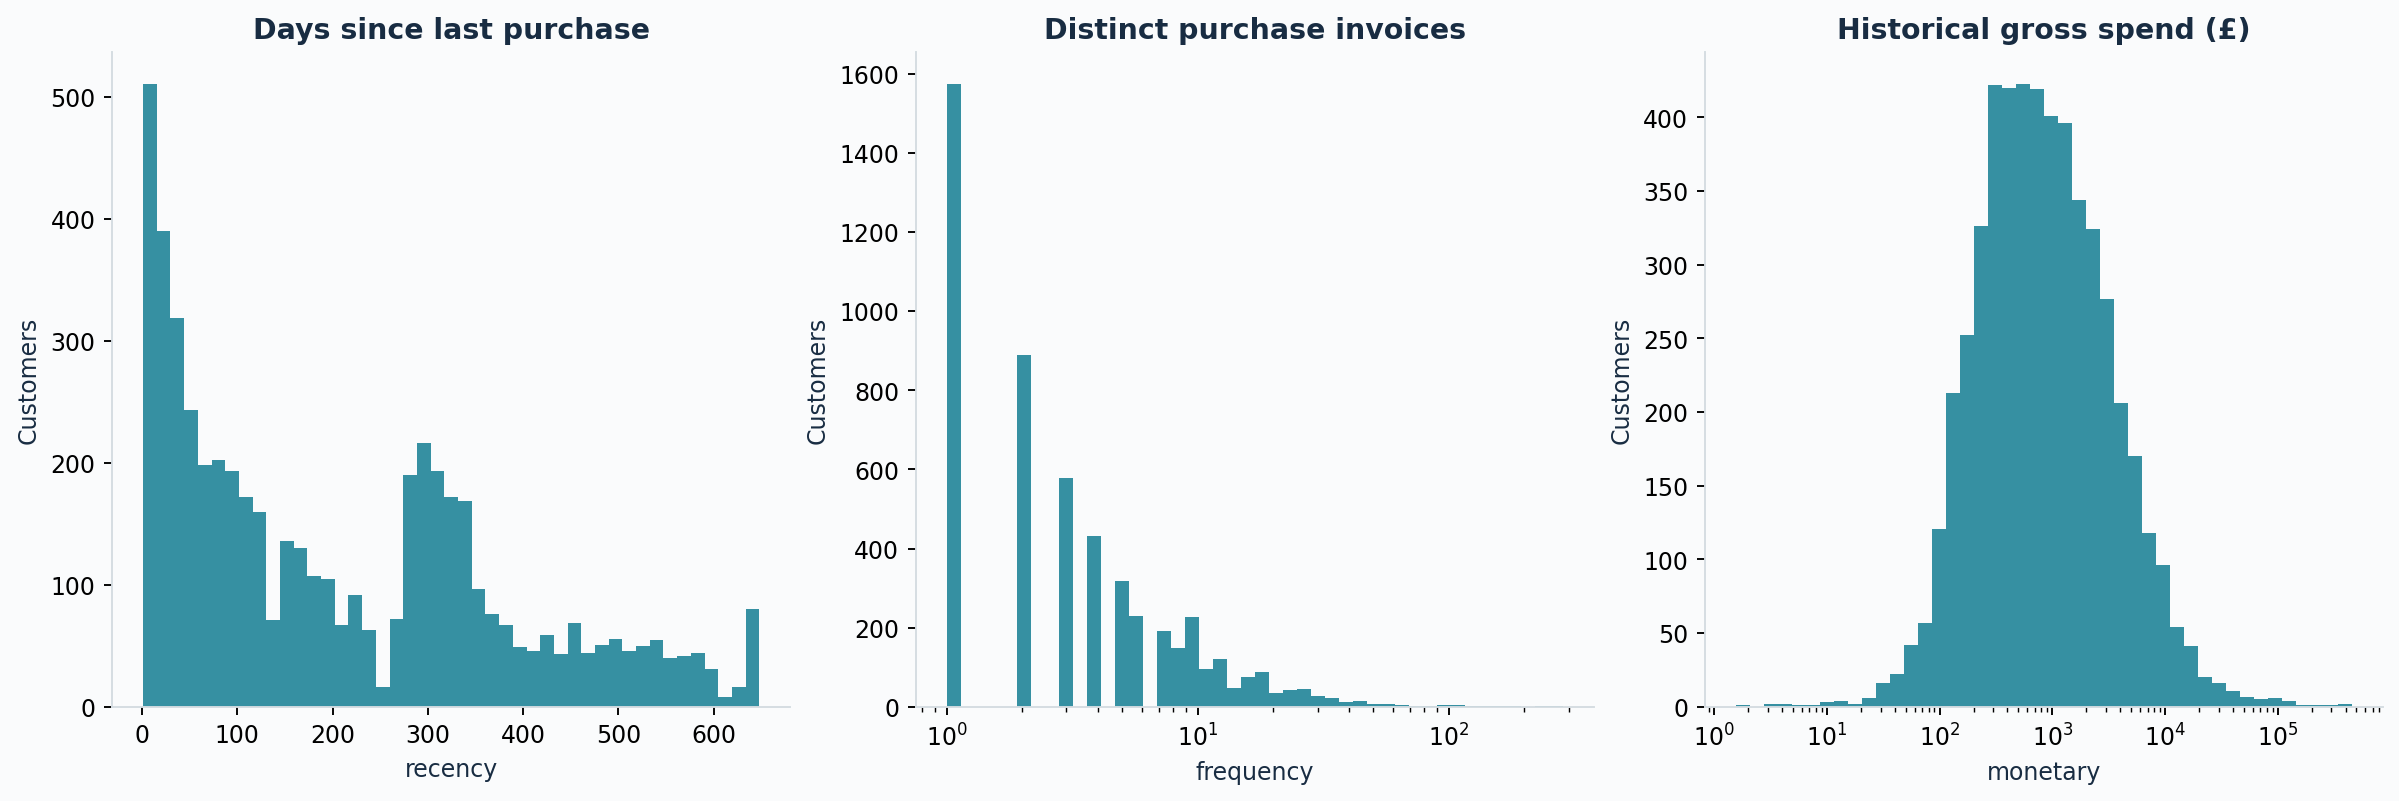

Raw distributions reveal skew; frequency and monetary axes are logarithmic. Reported monetary values remain uncapped.

## 6. Preprocessing and PCA
Ten features enter a historical-only transform: median imputation for missing gaps; 1st/99th percentile clipping and log1p for seven magnitudes; log1p for refund ratio; and z-score scaling. Rare flags are preserved. PCA retains at least 90% variance. See `src/modeling.py` for the fitted transformer and `docs/DATA_DICTIONARY.md` for definitions.


In [7]:
print("Model features:",", ".join(metrics["feature_names"]))
print("Retained components:",metrics["pca_components"])
print("Retained variance:",f"{metrics['pca_explained_variance']:.2%}")
print(pd.read_csv("outputs/pca_loadings.csv",index_col=0).round(3).to_string())


Model features: recency, frequency, monetary, unique_products, avg_basket_units, customer_age_days, avg_gap_days, return_value_ratio, recent_order_share, single_order
Retained components: 6
Retained variance: 92.92%
     recency  frequency  monetary  unique_products  avg_basket_units  customer_age_days  avg_gap_days  return_value_ratio  recent_order_share  single_order
PC1   -0.305      0.471     0.489            0.429             0.247              0.190        -0.113              -0.004               0.024        -0.389
PC2   -0.448     -0.037    -0.018           -0.023             0.057             -0.594        -0.120              -0.074               0.645         0.078
PC3    0.011     -0.199     0.050            0.131             0.439              0.034         0.631              -0.584               0.036         0.078
PC4    0.246     -0.195     0.166            0.093             0.712             -0.139        -0.301               0.350              -0.080         0.345
PC5 

## 7. Compare algorithms and cluster counts
Twenty-one fits use identical customer features. Silhouette uses a common fixed 1,500-customer sample. The campaign constraint requires 3+ groups, each ≥2% of customers and the largest ≤80%. A higher raw score with a tiny group does not satisfy that declared constraint. Elbow and BIC remain family-specific diagnostics.


In [8]:
comparison = pd.read_csv("outputs/model_comparison.csv")
print(comparison[["candidate","silhouette","davies_bouldin","smallest_cluster_share","eligible"]].round(4).to_string(index=False))
print("Selected:",metrics["selected_candidate"])
print("Selection rule:",metrics["selection_rule"])
print("80% subsample ARIs:",[round(v,4) for v in metrics["stability_80pct_subsample_ari"]])
print("Mean ARI:",round(metrics["stability_mean_ari"],4))


     candidate  silhouette  davies_bouldin  smallest_cluster_share  eligible
      KMeans_3      0.3233          1.1455                  0.0772      True
Hierarchical_3      0.3169          0.9808                  0.0575      True
      KMeans_4      0.3113          1.1607                  0.0769      True
Hierarchical_6      0.2900          1.2710                  0.0472      True
Hierarchical_5      0.2868          1.2481                  0.0472      True
Hierarchical_4      0.2736          1.2004                  0.0575      True
Hierarchical_7      0.2545          1.2231                  0.0472      True
         GMM_4      0.2408          2.4483                  0.0774      True
         GMM_3      0.2366          1.6083                  0.2997      True
         GMM_7      0.2257          1.7094                  0.0371      True
         GMM_6      0.2142          1.6506                  0.0371      True
         GMM_5      0.1945          2.5847                  0.0371      True

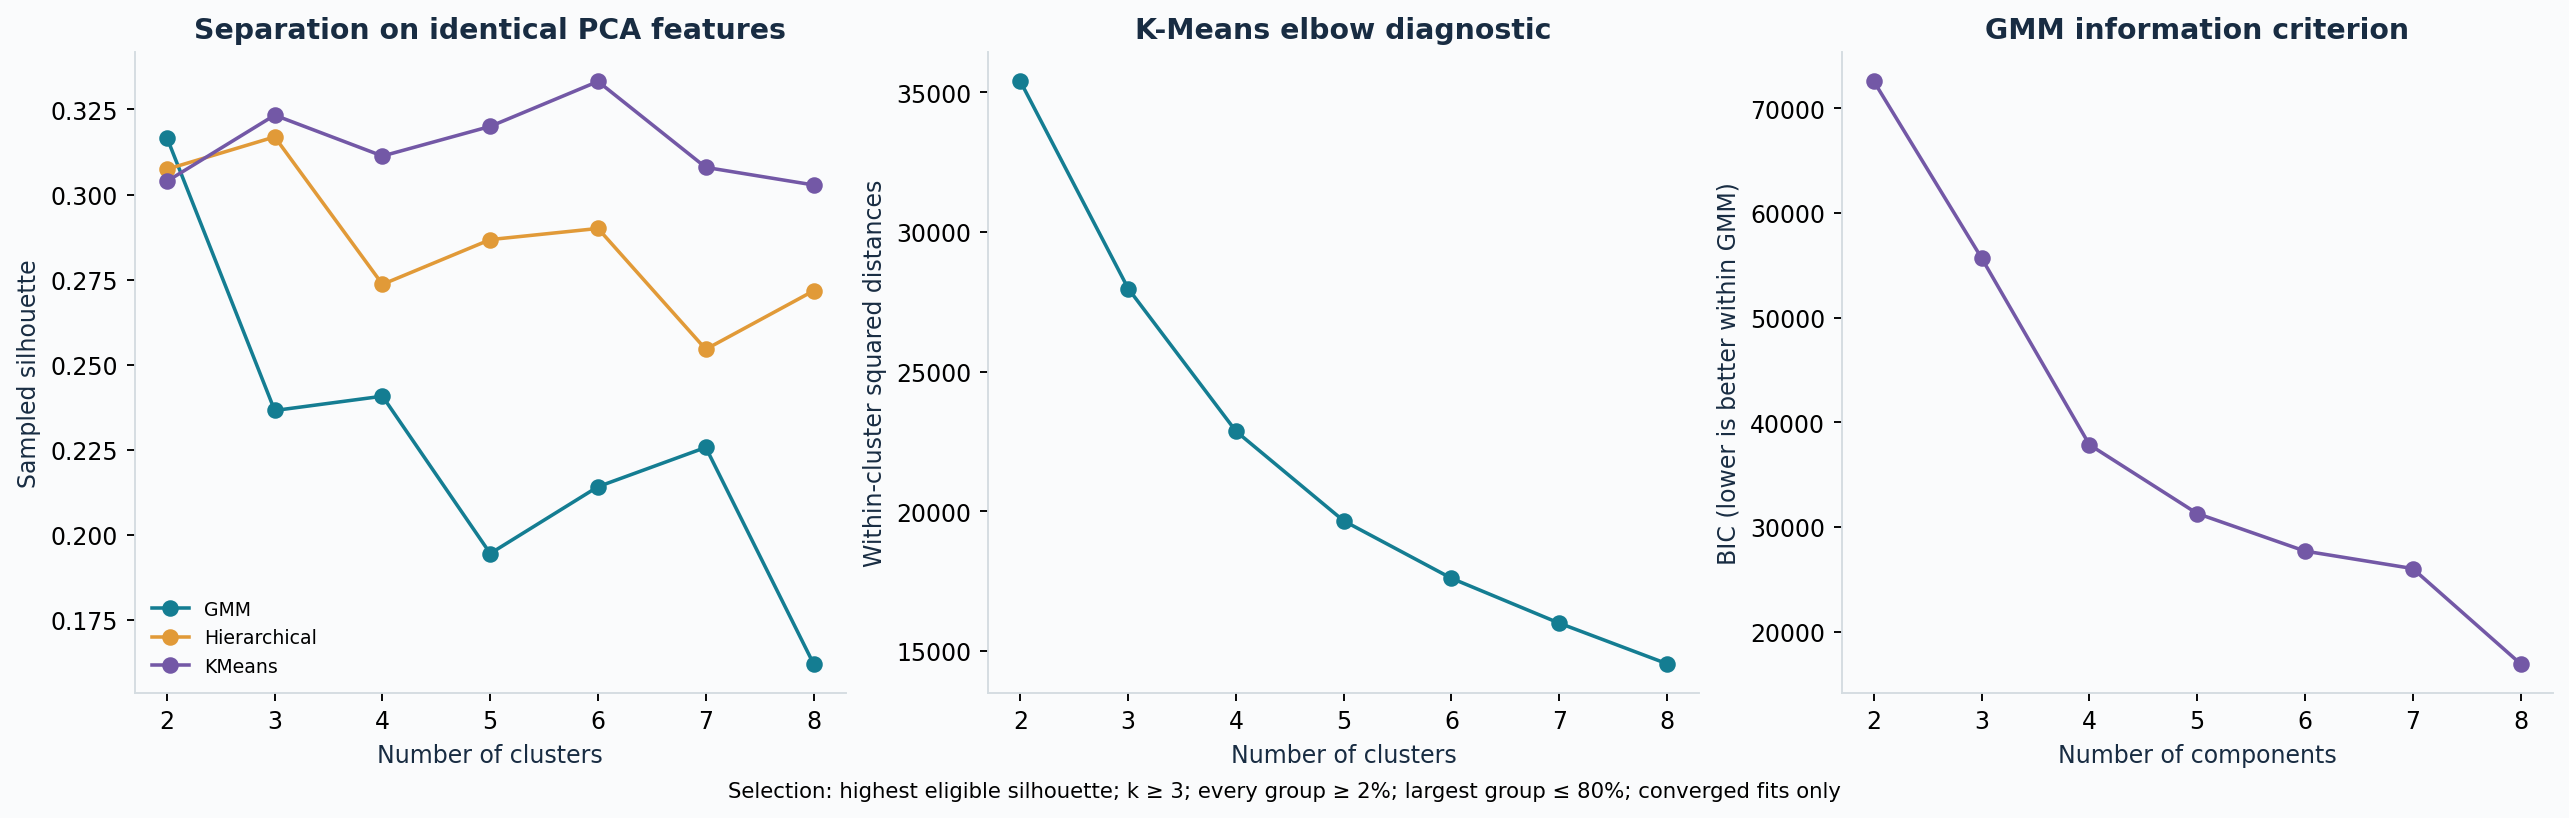

Algorithm comparisons use the same geometry. GMM BIC is not compared with K-Means inertia.

## 8. Interpret the clusters
Cluster IDs are arbitrary. Inspect original-unit medians and historical value shares. RFM personas are a separate transparent marketing overlay; they are not fabricated cluster labels.


In [9]:
print(pd.read_csv("outputs/cluster_profiles.csv").round(3).to_string(index=False))
print("\nPersona counts:")
print(customers.rfm_persona.value_counts().to_string())


 cluster  customers  median_recency  median_frequency  median_monetary  gross_value  avg_return_value_ratio  median_products  customer_share  gross_value_share
       0        406            27.0               1.0          405.735    237879.68                   0.010             24.0           0.077              0.017
       1       2333           319.0               1.0          320.690    937075.41                   0.029             19.0           0.444              0.068
       2       2517            72.0               6.0         2111.880  12515869.85                   0.022             91.0           0.479              0.914

Persona counts:
rfm_persona
Dormant / at-risk          2966
Developing / occasional     826
High-value loyal            507
At-risk high-value          398
Loyal repeat                366
New / first purchase        164
Recent high-value            29


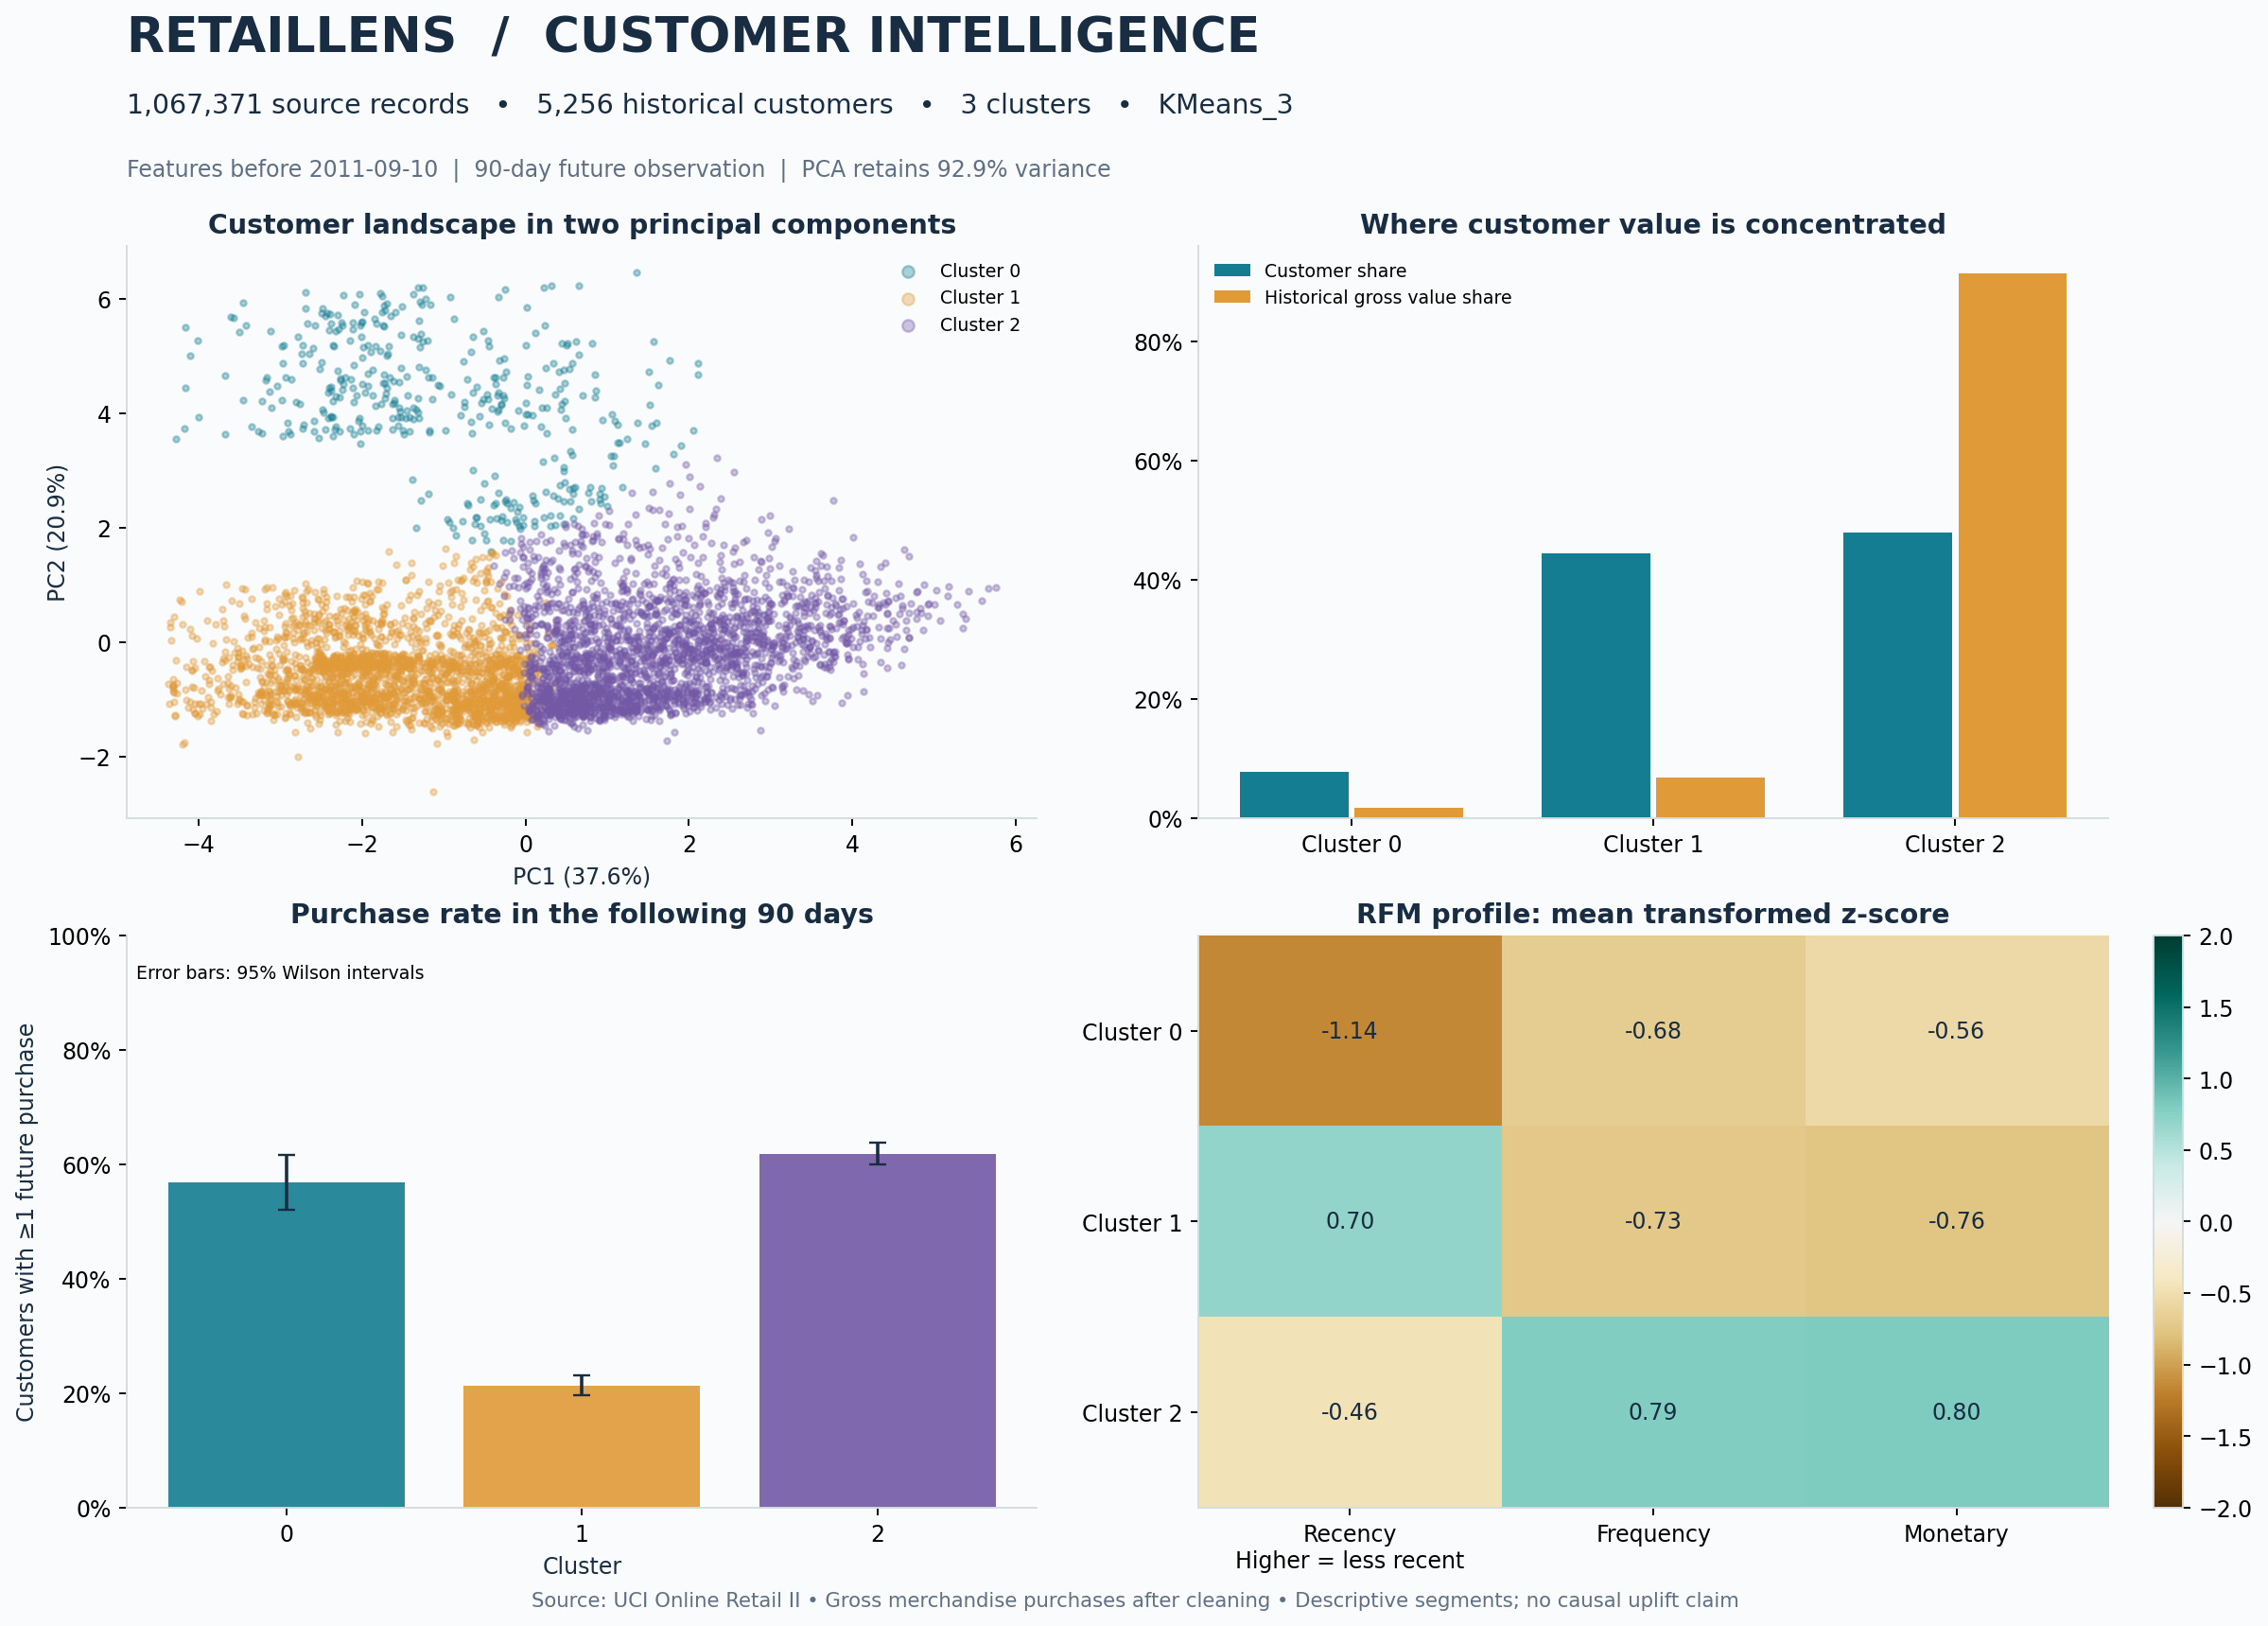

All measured results are observational. The two-dimensional view is a projection of the six-dimensional fitted representation.

## 9. Observe the untouched future period
This checks whether historical segments have different future purchasing. It does not measure campaign lift, supervised prediction accuracy or churn. Inactive historical customers remain in the denominator. Future first-time customers are excluded.


In [10]:
print("Holdout:",metrics["cutoff_exclusive"],"inclusive →",metrics["holdout_end_exclusive"],"exclusive")
print(pd.read_csv("outputs/holdout_by_cluster.csv").round(4).to_string(index=False))
print("\nRFM persona outcomes:")
print(pd.read_csv("outputs/holdout_by_persona.csv").round(4).to_string(index=False))


Holdout: 2011-09-10 inclusive → 2011-12-09 exclusive
 cluster  customers  buyers  purchase_rate  avg_future_gross_value  total_future_gross_value  purchase_rate_ci_low  purchase_rate_ci_high
       0        406     231         0.5690                491.1830                 199420.28                0.5204                 0.6163
       1       2333     498         0.2135                 84.0582                 196107.72                0.1973                 0.2306
       2       2517    1558         0.6190                958.4869                2412511.41                0.5999                 0.6378

RFM persona outcomes:
            rfm_persona  customers  buyers  purchase_rate  avg_future_gross_value  total_future_gross_value  purchase_rate_ci_low  purchase_rate_ci_high
     At-risk high-value        398     212         0.5327                595.2762                 236919.92                0.4836                 0.5811
Developing / occasional        826     471         0.5702         

## 10. Review monthly cohorts
A cohort means first observed purchase month, not verified acquisition month. Grey cells are unobserved future periods; observed inactivity is zero. The incomplete final month is omitted. This descriptive table includes available full months and is not used to fit or select clusters.


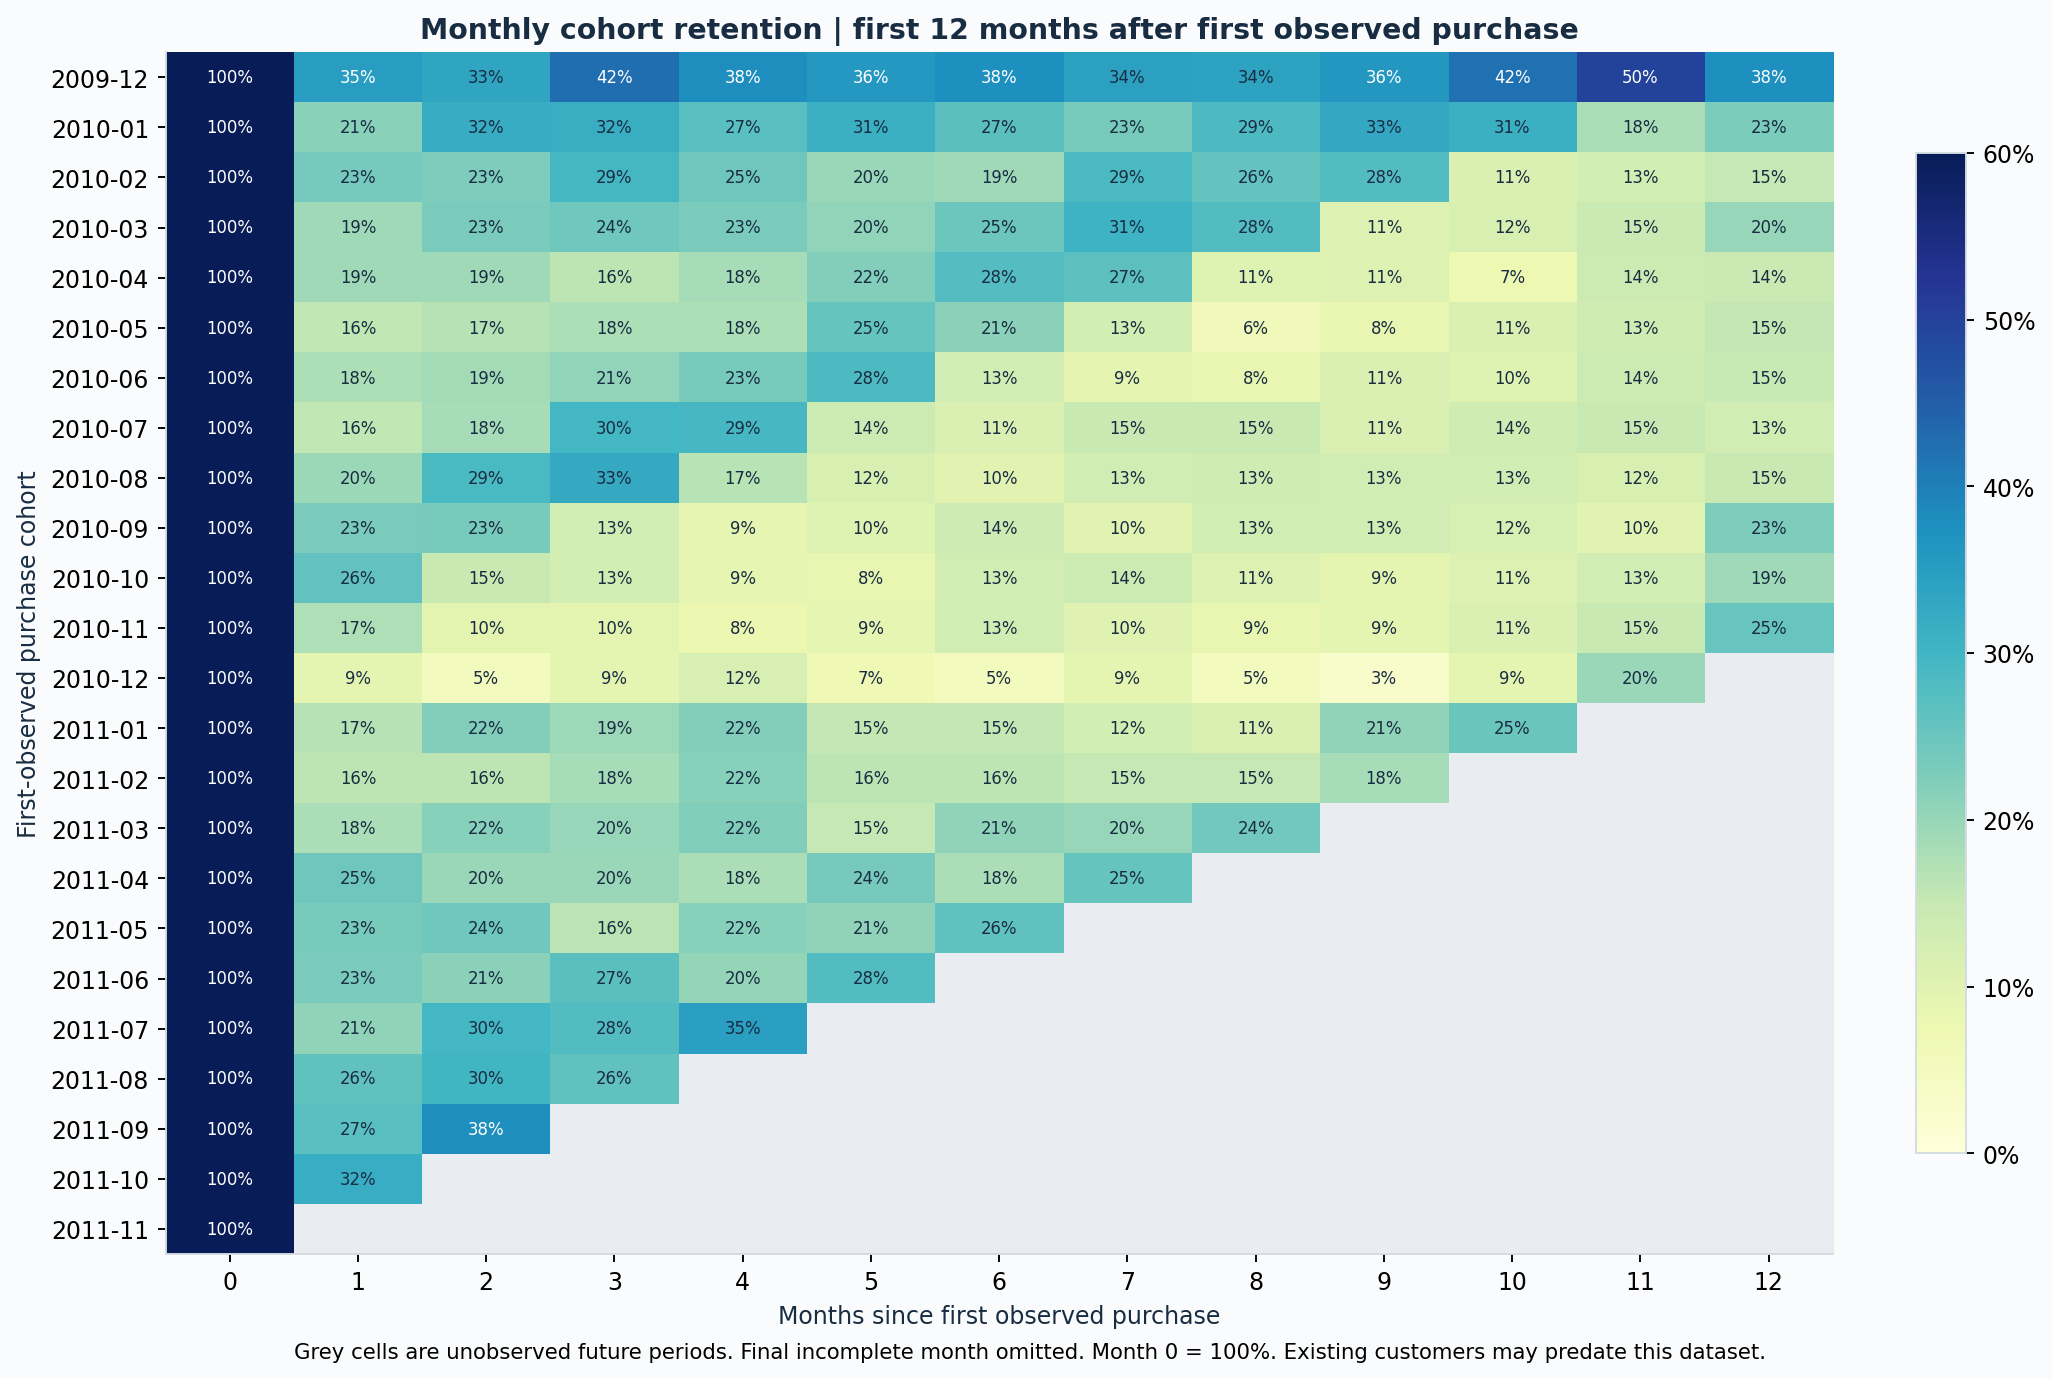

Monthly retention = active customers from the original cohort / original cohort size. Month 0 is 100%.

## 11. Verify persisted scoring
The selected K-Means artifact contains historical preprocessing and PCA. Native `predict` should reproduce the delivered historical labels. If a future run selects hierarchical clustering, unseen customers use a documented nearest-centroid approximation instead; that approximation need not reproduce Ward labels exactly.


In [11]:
scored_path = Path("outputs/scoring_check.csv")
scoring = subprocess.run([RUN_PY,"score.py","outputs/customer_segments.csv","--output",str(scored_path)],check=True,capture_output=True,text=True)
print(scoring.stdout)
scored = pd.read_csv(scored_path,dtype={"customer_id":str})
agreement = (customers.cluster.to_numpy() == scored.cluster.to_numpy()).mean()
print("Saved-model assignment agreement:",f"{agreement:.2%}")
if metrics["algorithm"] != "Hierarchical":
    assert agreement == 1.0
scored_path.unlink()


Saved 5,256 assignments to outputs/scoring_check.csv. Native model predict

Saved-model assignment agreement: 100.00%


## 12. Turn findings into a testable action
Propose personalized win-back for high-value inactive customers, second-purchase onboarding for new customers, and replenishment/early access for valuable repeat buyers. Randomize within each persona and measure incremental results against a control; track discount cost, returns and opt-outs. This dataset lacks margin and campaign exposure.

Read `outputs/REPORT.md` for the full evidence and limitations. Read `docs/INTERVIEW_GUIDE.md` before using the resume bullets.

**Attribution:** Chen, D. (2012), Online Retail II, UCI Machine Learning Repository, https://doi.org/10.24432/C5CG6D . CC BY 4.0. No simulated data was used for the full-data analysis.


In [12]:
print(Path("outputs/RESUME_BULLETS.md").read_text())


# RetailLens — RFM Customer Segmentation & Retention Analytics

- Engineered SQL-based RFM and behavioral features from 1.07M retail transaction records using joins, aggregations and window functions, modeling 5,256 historical customers after auditable cleaning.
- Benchmarked K-Means, Ward hierarchical clustering and Gaussian mixture models across 2–8 clusters; selected a 3-segment KMeans solution with 0.323 silhouette and 0.965 mean subsampling ARI.
- Reduced 10 features to 6 principal components (92.9% variance retained), profiled RFM personas and evaluated segment purchase behavior on an untouched 90-day holdout.

Use these only after you have reviewed the code and can explain the methodology. These results measure separation and stability, not classification accuracy or business uplift. '1.07M records' means raw line items, not unique orders. The selected model describes customers observed before 2011-09-10; it does not use the future period for feature fitting.

